In [1]:
import os
import io
import gc
import json
import math
import random
import shutil
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image, ImageOps, ImageEnhance, ImageFilter, ImageCms, ImageFile
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, confusion_matrix, balanced_accuracy_score, accuracy_score, f1_score, precision_score, recall_score, brier_score_loss

try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass

try:
    import pillow_avif
except ImportError:
    pass

ImageFile.LOAD_TRUNCATED_IMAGES = False
Image.MAX_IMAGE_PIXELS = 160000000
warnings.filterwarnings("ignore", category=Image.DecompressionBombWarning)

SEED = 20261012
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy("float32")

ROOT = Path.cwd()
AUDIT = ROOT / "dataset_audit"
with (AUDIT / "audit_summary.json").open(encoding="utf-8") as stream:
    AUDIT_DATA = json.load(stream)
DATASET = Path(AUDIT_DATA["root"]).expanduser()
if not DATASET.is_dir():
    DATASET = next((p for p in [ROOT / "dataset", ROOT / "datasets"] if p.is_dir()), DATASET)
if not DATASET.is_dir():
    raise FileNotFoundError(f"Dataset not found: {DATASET}")

OUT = ROOT / "model_artifacts"
CHECKPOINTS = OUT / "checkpoints"
REPORTS = OUT / "reports"
for directory in (OUT, CHECKPOINTS, REPORTS):
    directory.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 16
NUM_CPU_WORKERS = 4
STAGES = [
    {"size": 256, "epochs": 20, "peak_lr": 0.0003, "min_lr": 0.000008, "patience": 8},
    {"size": 320, "epochs": 15, "peak_lr": 0.00009, "min_lr": 0.000003, "patience": 7}
]
WEIGHT_DECAY = 0.00007
LABEL_SMOOTHING = 0.012
PLOT_BG = "#080F1C"
PANEL_BG = "#111D31"
CYAN = "#4FD9E7"
ORANGE = "#FFA86B"
WHITE = "#EEF5FF"
MUTED = "#91A4C2"

print(f"TensorFlow {tf.__version__} | GPU: {tf.config.list_physical_devices('GPU')}")
print(f"DATASET: {DATASET}")
print(f"OUTPUT: {OUT}")
print(f"Batch: {BATCH_SIZE} | Stages: {STAGES}")

TensorFlow 2.18.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
DATASET: /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/dataset
OUTPUT: /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts
Batch: 16 | Stages: [{'size': 256, 'epochs': 20, 'peak_lr': 0.0003, 'min_lr': 8e-06, 'patience': 8}, {'size': 320, 'epochs': 15, 'peak_lr': 9e-05, 'min_lr': 3e-06, 'patience': 7}]


In [2]:
manifest = pd.read_csv(AUDIT / "dataset_manifest.csv", keep_default_na=True)
manifest = manifest.loc[(manifest["status"] == "ok") & (manifest["split"].isin(["train", "validation"]))].copy()
manifest["absolute_path"] = manifest["path"].map(lambda x: str(DATASET / str(x)))
if manifest["absolute_path"].map(lambda x: Path(x).is_file()).sum() != len(manifest):
    missing = manifest.loc[~manifest["absolute_path"].map(lambda x: Path(x).is_file()), "path"].head(15).tolist()
    raise FileNotFoundError(f"These images cannot be found: {missing}")

train_frame = manifest.loc[manifest["split"] == "train"].copy()
val_frame = manifest.loc[manifest["split"] == "validation"].copy()

if train_frame.duplicated("checksum").any():
    train_frame = train_frame.drop_duplicates("checksum", keep="first").copy()

heldout_checksums = set(val_frame["checksum"].astype(str))
leaky = train_frame["checksum"].astype(str).isin(heldout_checksums)
print("Removed exact train duplicates overlapping validation:", int(leaky.sum()))
train_frame = train_frame.loc[~leaky].copy()

near_csv = AUDIT / "near_duplicate_candidates.csv"
if near_csv.exists():
    near = pd.read_csv(near_csv)
    if len(near) and {"train", "distance"}.issubset(near.columns):
        flagged = set(near.loc[near["distance"] <= 3, "train"].astype(str))
        drop = train_frame["path"].isin(flagged)
        print("Excluded training images matching suspicious cross-split near pairs:", int(drop.sum()))
        train_frame = train_frame.loc[~drop].copy()

real_suspects = train_frame.loc[(train_frame["label"] == 0) & train_frame["path"].str.contains(r"screenshot|screen.?shot|pasted|generated", case=False, na=False), ["path", "decoded_format"]]
real_suspects.to_csv(REPORTS / "potential_real_label_review.csv", index=False)
print("Real-labeled images for manual source review:", len(real_suspects))
print(real_suspects.head(12).to_string(index=False))

if len(set(train_frame["checksum"]) & set(val_frame["checksum"])):
    raise AssertionError("Cross-split duplicate leakage remains")
if train_frame["label"].value_counts().min() < 2 or val_frame["label"].value_counts().min() < 2:
    raise ValueError("Expected both classes in each split")

print("Train:", train_frame["label"].value_counts().sort_index().to_dict())
print("Validation:", val_frame["label"].value_counts().sort_index().to_dict())
print(f"Source-format-only baseline: AUC={AUDIT_DATA['metadata_probe']['auc']:.6f}; do not treat in-distribution validation as independent forensic evidence")
train_frame[["path", "label"]].to_csv(REPORTS / "effective_train_manifest.csv", index=False)
val_frame[["path", "label"]].to_csv(REPORTS / "validation_manifest.csv", index=False)

Removed exact train duplicates overlapping validation: 1
Excluded training images matching suspicious cross-split near pairs: 0
Real-labeled images for manual source review: 330
                                               path decoded_format
train/Real_images/Pasted 2026-10-03 at 01.53.05.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.53.21.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.53.36.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.53.47.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.58.03.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.58.14.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.58.24.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.58.30.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.58.42.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.58.55.png            PNG
train/Real_images/Pasted 2026-10-03 at 01.59.04.png            PNG
train/Real_images/

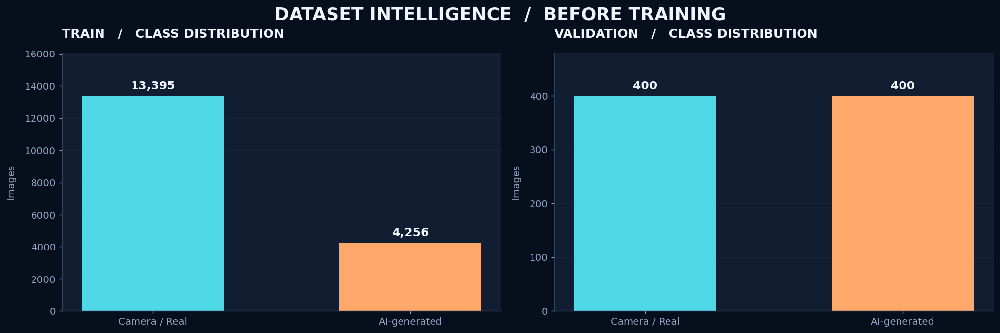

In [3]:
def display_style():
    plt.rcParams.update({
        "figure.facecolor": PLOT_BG, "axes.facecolor": PANEL_BG,
        "savefig.facecolor": PLOT_BG, "axes.edgecolor": "#31425D",
        "axes.labelcolor": WHITE, "text.color": WHITE,
        "xtick.color": MUTED, "ytick.color": MUTED,
        "grid.color": "#354561", "grid.alpha": 0.22,
        "font.family": "DejaVu Sans", "font.size": 11,
        "axes.titlesize": 14, "axes.titleweight": "bold",
        "axes.spines.top": False, "axes.spines.right": False,
        "figure.dpi": 130, "savefig.dpi": 190
    })

def decorate(ax, title, xlabel=None, ylabel=None):
    ax.set_title(title, loc="left", pad=17, color=WHITE, fontweight="bold")
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, labelpad=10)
    if ylabel:
        ax.set_ylabel(ylabel, color=MUTED, labelpad=10)
    ax.grid(axis="y", alpha=0.16)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_color("#33445F")

def save_plot(fig, name):
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", facecolor=PLOT_BG)
    fig.savefig(REPORTS / f"{name}.svg", bbox_inches="tight", facecolor=PLOT_BG)
    plt.show()
    plt.close(fig)

display_style()
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.1), layout="constrained")
for ax, (section, frame) in zip(axes, [("TRAIN", train_frame), ("VALIDATION", val_frame)]):
    counts = frame["label"].value_counts().reindex([0, 1], fill_value=0)
    bars = ax.bar(["Camera / Real", "AI-generated"], counts.values, color=[CYAN, ORANGE], width=0.55)
    for bar, value in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, value + counts.max() * 0.03, f"{value:,}", ha="center", fontsize=13, color=WHITE, fontweight="bold")
    ax.set_ylim(0, counts.max() * 1.2)
    decorate(ax, f"{section}   /   CLASS DISTRIBUTION", ylabel="Images")
fig.suptitle("DATASET INTELLIGENCE  /  BEFORE TRAINING", fontsize=20, fontweight="bold", color=WHITE)
save_plot(fig, "01_dataset_composition")

In [4]:
def rgb_open(path, background=255):
    with Image.open(path) as source:
        try:
            source.draft("RGB", (800, 800))
        except Exception:
            pass
        source.seek(0)
        image = ImageOps.exif_transpose(source)
        profile = image.info.get("icc_profile")
        if image.mode not in ("RGB", "RGBA"):
            image = image.convert("RGBA" if "A" in image.getbands() else "RGB")
        if profile and image.mode == "RGB":
            try:
                profile_input = ImageCms.ImageCmsProfile(io.BytesIO(profile))
                image = ImageCms.profileToProfile(image, profile_input, ImageCms.createProfile("sRGB"), outputMode="RGB")
            except Exception:
                pass
        if image.mode == "RGBA":
            base = Image.new("RGBA", image.size, (background, background, background, 255))
            image = Image.alpha_composite(base, image).convert("RGB")
        elif image.mode != "RGB":
            image = image.convert("RGB")
        return image.copy()

def square_crop(image, size, train=False, rng=None, variant="center"):
    w, h = image.size
    side = min(w, h)
    if train:
        crop_side = max(1, int(side * float(rng.uniform(0.72, 1.0))))
        left = int(rng.integers(0, w - crop_side + 1))
        top = int(rng.integers(0, h - crop_side + 1))
    else:
        crop_side = side
        if variant == "corner_tl":
            left, top = 0, 0
        elif variant == "corner_br":
            left, top = w - side, h - side
        else:
            left, top = (w - side) // 2, (h - side) // 2
    image = image.crop((left, top, left + crop_side, top + crop_side))
    return image.resize((size, size), Image.Resampling.LANCZOS)

def stochastic_transform(image, rng):
    if rng.random() < 0.5:
        image = ImageOps.mirror(image)
    if rng.random() < 0.35:
        image = ImageEnhance.Brightness(image).enhance(float(rng.uniform(0.89, 1.11)))
    if rng.random() < 0.35:
        image = ImageEnhance.Contrast(image).enhance(float(rng.uniform(0.89, 1.11)))
    if rng.random() < 0.30:
        image = ImageEnhance.Color(image).enhance(float(rng.uniform(0.85, 1.15)))
    if rng.random() < 0.04:
        image = ImageOps.grayscale(image).convert("RGB")
    if rng.random() < 0.25:
        scale = float(rng.uniform(0.65, 0.94))
        small = max(64, int(image.width * scale))
        image = image.resize((small, small), Image.Resampling.BICUBIC).resize(image.size, Image.Resampling.BICUBIC)
    if rng.random() < 0.23:
        image = image.filter(ImageFilter.GaussianBlur(radius=float(rng.uniform(0.12, 0.67))))
    if rng.random() < 0.11:
        image = image.filter(ImageFilter.UnsharpMask(radius=1.2, percent=int(rng.integers(60, 135)), threshold=2))
    if rng.random() < 0.78:
        output = io.BytesIO()
        image.save(output, format="JPEG", quality=int(rng.integers(57, 97)), subsampling=int(rng.choice([0, 1, 2])), optimize=False)
        output.seek(0)
        with Image.open(output) as encoded:
            image = encoded.convert("RGB")
    data = np.asarray(image, dtype=np.float32) / 255.0
    if rng.random() < 0.24:
        sigma = float(rng.uniform(0.002, 0.015))
        data = np.clip(data + rng.normal(0, sigma, data.shape).astype(np.float32), 0, 1)
    return np.ascontiguousarray(data, dtype=np.float32)

def load_train_image(path_tensor, index_tensor, size):
    filepath = path_tensor.numpy().decode("utf-8")
    index = int(index_tensor.numpy())
    rng = np.random.default_rng(np.random.SeedSequence([SEED, index]))
    background = int(rng.choice([0, 127, 255]))
    image = rgb_open(filepath, background)
    image = square_crop(image, size, train=True, rng=rng)
    return stochastic_transform(image, rng)

def load_evaluation_image(path_tensor, size, variant="center"):
    filepath = path_tensor.numpy().decode("utf-8")
    image = square_crop(rgb_open(filepath, 255), size, variant=variant)
    if variant == "jpeg80":
        output = io.BytesIO()
        image.save(output, format="JPEG", quality=80, subsampling=2)
        output.seek(0)
        with Image.open(output) as enc:
            image = enc.convert("RGB")
    if variant == "softened":
        image = image.filter(ImageFilter.GaussianBlur(radius=0.65))
    return np.asarray(image, dtype=np.float32) / 255.0

print("Image loading and uniform class-independent augmentation functions ready")

Image loading and uniform class-independent augmentation functions ready


Training steps per epoch: 1104
Balanced random sampling prevents majority-class-dominated batches


2026-10-12 02:47:22.053641: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Pro
2026-10-12 02:47:22.053673: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-10-12 02:47:22.053676: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.88 GB
I0000 00:00:1791760642.053886   12533 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791760642.053932   12533 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


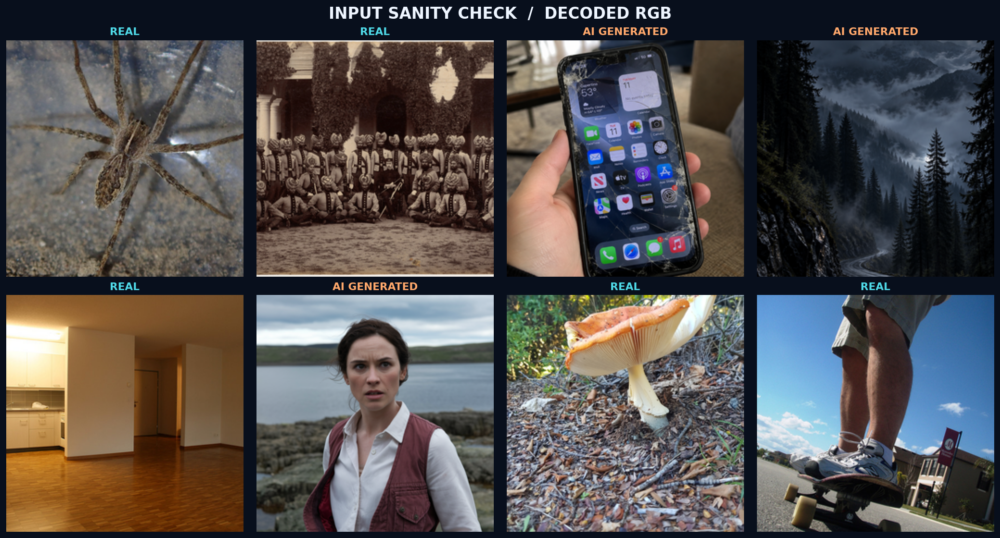

In [5]:
AUTOTUNE = tf.data.AUTOTUNE

def image_dataset(frame, size, training=False, variant="center"):
    if training:
        real = frame.loc[frame["label"] == 0, "absolute_path"].to_numpy(dtype=str)
        ai = frame.loc[frame["label"] == 1, "absolute_path"].to_numpy(dtype=str)
        streams = [
            tf.data.Dataset.from_tensor_slices(real).shuffle(len(real), seed=SEED, reshuffle_each_iteration=True).repeat(),
            tf.data.Dataset.from_tensor_slices(ai).shuffle(len(ai), seed=SEED + 1, reshuffle_each_iteration=True).repeat()
        ]
        ds = tf.data.Dataset.sample_from_datasets(streams, weights=[0.5, 0.5], seed=SEED)
        ds = ds.enumerate()
        def decode(idx, filename):
            image = tf.py_function(lambda a, b: load_train_image(a, b, size), [filename, idx], tf.float32)
            image.set_shape([size, size, 3])
            label = tf.cast(tf.strings.regex_full_match(filename, ".*/AI_images/.*"), tf.float32)
            return image, tf.reshape(label, [1])
        ds = ds.map(decode, num_parallel_calls=NUM_CPU_WORKERS, deterministic=True)
    else:
        paths = frame["absolute_path"].to_numpy(dtype=str)
        labels = frame["label"].to_numpy(dtype=np.float32)
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))
        def decode(filename, label):
            image = tf.py_function(lambda f: load_evaluation_image(f, size, variant), [filename], tf.float32)
            image.set_shape([size, size, 3])
            return image, tf.reshape(tf.cast(label, tf.float32), [1])
        ds = ds.map(decode, num_parallel_calls=NUM_CPU_WORKERS, deterministic=True)
    options = tf.data.Options()
    options.experimental_deterministic = True
    ds = ds.with_options(options)
    ds = ds.batch(BATCH_SIZE, drop_remainder=training).prefetch(2)
    return ds

train_steps = math.ceil(len(train_frame) / BATCH_SIZE)
val_labels = val_frame["label"].to_numpy(dtype=np.int32)
print("Training steps per epoch:", train_steps)
print("Balanced random sampling prevents majority-class-dominated batches")
small_train = train_frame.sample(min(8, len(train_frame)), random_state=SEED).copy()
sample_ds = image_dataset(small_train, 256, training=False)
images, labels = next(iter(sample_ds))
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5), layout="constrained")
for ax, img, lab in zip(axes.flat, images.numpy(), labels.numpy().reshape(-1)):
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title("AI GENERATED" if lab else "REAL", color=ORANGE if lab else CYAN, fontsize=12)
    ax.axis("off")
for ax in list(axes.flat)[len(images):]:
    ax.axis("off")
fig.suptitle("INPUT SANITY CHECK  /  DECODED RGB", fontsize=18, weight="bold")
save_plot(fig, "02_input_sanity")

In [6]:
K = tf.keras
L = K.layers

def conv_bn(x, filters, kernel=3, stride=1, activation=True, name="conv"):
    x = L.Conv2D(filters, kernel, strides=stride, padding="same", use_bias=False, kernel_initializer="he_normal", name=f"{name}_conv")(x)
    x = L.BatchNormalization(momentum=0.92, epsilon=1e-5, name=f"{name}_bn")(x)
    if activation:
        x = L.Activation("swish", name=f"{name}_act")(x)
    return x

def residual_unit(x, filters, stride, drop, name):
    skip = x
    y = conv_bn(x, filters, 3, stride, name=f"{name}_a")
    y = L.SpatialDropout2D(drop, name=f"{name}_spatial_dropout")(y) if drop > 0 else y
    y = conv_bn(y, filters, 3, 1, activation=False, name=f"{name}_b")
    if stride != 1 or x.shape[-1] != filters:
        skip = conv_bn(skip, filters, 1, stride, activation=False, name=f"{name}_projection")
    y = L.Add(name=f"{name}_add")([skip, y])
    return L.Activation("swish", name=f"{name}_out")(y)

def build_cnn():
    inputs = L.Input(shape=(None, None, 3), name="normalized_rgb")
    x = conv_bn(inputs, 32, 5, 2, name="stem_a")
    x = conv_bn(x, 32, 3, 1, name="stem_b")
    for stage, (filters, depth, dropout) in enumerate([(32, 2, 0.00), (64, 2, 0.025), (104, 3, 0.045), (168, 3, 0.065), (248, 2, 0.085)], 1):
        for block in range(depth):
            stride = 2 if stage > 1 and block == 0 else 1
            x = residual_unit(x, filters, stride, dropout, f"stage{stage}_block{block + 1}")
    x = conv_bn(x, 320, 1, 1, name="forensic_features")
    x = L.GlobalAveragePooling2D(name="global_pool")(x)
    x = L.Dropout(0.37, name="classifier_dropout")(x)
    x = L.Dense(144, activation="swish", name="classifier_dense")(x)
    x = L.Dropout(0.22, name="classifier_dropout_2")(x)
    output = L.Dense(1, activation="sigmoid", dtype="float32", name="ai_probability")(x)
    return K.Model(inputs=inputs, outputs=output, name="AegisCNN_FromScratch")

model = build_cnn()
model.summary(line_length=112)
print("Trainable parameters:", f"{model.count_params():,}")

Model: "AegisCNN_FromScratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                   ┃ Output Shape               ┃          Param # ┃ Connected to                ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ normalized_rgb (InputLayer)    │ (None, None, None, 3)      │                0 │ -                           │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stem_a_conv (Conv2D)           │ (None, None, None, 32)     │            2,400 │ normalized_rgb[0][0]        │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stem_a_bn (BatchNormalization) │ (None, None, None, 32)     │              128 │ stem_a_conv[0][0]           │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stem_a_act (Activation)        │ (None, None, None, 32)     │                0 │ stem_a_bn[0][0]             │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stem_b_conv (Conv2D)           │ (None, None, None, 32)     │            9,216 │ stem_a_act[0][0]            │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stem_b_bn (BatchNormalization) │ (None, None, None, 32)     │              128 │ stem_b_conv[0][0]           │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stem_b_act (Activation)        │ (None, None, None, 32)     │                0 │ stem_b_bn[0][0]             │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block1_a_conv (Conv2D)  │ (None, None, None, 32)     │            9,216 │ stem_b_act[0][0]            │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block1_a_bn             │ (None, None, None, 32)     │              128 │ stage1_block1_a_conv[0][0]  │
│ (BatchNormalization)           │                            │                  │                             │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block1_a_act            │ (None, None, None, 32)     │                0 │ stage1_block1_a_bn[0][0]    │
│ (Activation)                   │                            │                  │                             │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block1_b_conv (Conv2D)  │ (None, None, None, 32)     │            9,216 │ stage1_block1_a_act[0][0]   │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block1_b_bn             │ (None, None, None, 32)     │              128 │ stage1_block1_b_conv[0][0]  │
│ (BatchNormalization)           │                            │                  │                             │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block1_add (Add)        │ (None, None, None, 32)     │                0 │ stem_b_act[0][0],           │
│                                │                            │                  │ stage1_block1_b_bn[0][0]    │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block1_out (Activation) │ (None, None, None, 32)     │                0 │ stage1_block1_add[0][0]     │
├────────────────────────────────┼────────────────────────────┼──────────────────┼─────────────────────────────┤
│ stage1_block2_a_conv (Conv2D)  │ (None, Non

 Total params: 4,396,513 (16.77 MB)

 Trainable params: 4,388,561 (16.74 MB)

 Non-trainable params: 7,952 (31.06 KB)

Trainable parameters: 4,396,513


In [7]:
probe_dataset = image_dataset(train_frame, 256, training=True)
probe_x, probe_y = next(iter(probe_dataset))
with tf.GradientTape() as tape:
    probe_output = model(probe_x, training=True)
    probe_loss = tf.reduce_mean(K.losses.binary_crossentropy(probe_y, probe_output))
probe_grads = tape.gradient(probe_loss, model.trainable_variables)
if not np.isfinite(float(probe_loss.numpy())):
    raise FloatingPointError("The forward-pass loss is not finite")
if any(grad is None for grad in probe_grads):
    raise RuntimeError("One or more CNN variables have no training gradient")
if not all(bool(tf.reduce_all(tf.math.is_finite(grad)).numpy()) for grad in probe_grads):
    raise FloatingPointError("Non-finite gradients detected during the TensorFlow Metal preflight")
print(f"FORWARD/BACKWARD PREFLIGHT PASS | Loss {float(probe_loss.numpy()):.4f} | {len(probe_grads)} trainable tensors")
del probe_dataset, probe_x, probe_y, probe_grads, probe_output

FORWARD/BACKWARD PREFLIGHT PASS | Loss 0.7358 | 97 trainable tensors


In [8]:
def compile_model(network, lr):
    optimizer = K.optimizers.AdamW(learning_rate=lr, weight_decay=WEIGHT_DECAY, global_clipnorm=1.0)
    if hasattr(optimizer, "exclude_from_weight_decay"):
        optimizer.exclude_from_weight_decay(var_names=["bias", "beta", "gamma"])
    network.compile(
        optimizer=optimizer,
        loss=K.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=[
            K.metrics.BinaryAccuracy(name="accuracy"),
            K.metrics.AUC(name="auc", curve="ROC", num_thresholds=500),
            K.metrics.AUC(name="pr_auc", curve="PR", num_thresholds=500),
            K.metrics.Precision(name="precision"),
            K.metrics.Recall(name="recall")
        ],
        jit_compile=False
    )

def learning_schedule(epoch, peak, minimum, total_epochs):
    warmup = min(2, max(1, total_epochs // 6))
    if epoch < warmup:
        return float(peak * (0.3 + 0.7 * (epoch + 1) / warmup))
    fraction = min(1.0, (epoch - warmup) / max(1, total_epochs - warmup - 1))
    return float(minimum + 0.5 * (peak - minimum) * (1 + math.cos(math.pi * fraction)))

history_per_stage = {}
for stage_number, settings in enumerate(STAGES, 1):
    size = settings["size"]
    epochs = settings["epochs"]
    checkpoint_path = CHECKPOINTS / f"stage{stage_number}_best.keras"
    print("=" * 75)
    print(f"STAGE {stage_number}/{len(STAGES)} | {size} px | max {epochs} epochs")
    print("=" * 75)
    compile_model(model, settings["peak_lr"])
    train_ds = image_dataset(train_frame, size, training=True)
    val_ds = image_dataset(val_frame, size, training=False)
    callbacks = [
        K.callbacks.LearningRateScheduler(lambda epoch, _, s=settings: learning_schedule(epoch, s["peak_lr"], s["min_lr"], s["epochs"]), verbose=0),
        K.callbacks.ModelCheckpoint(str(checkpoint_path), monitor="val_loss", mode="min", save_best_only=True, verbose=1),
        K.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=settings["patience"], min_delta=0.0002, restore_best_weights=True, verbose=1),
        K.callbacks.CSVLogger(str(REPORTS / f"stage{stage_number}_history.csv"))
    ]
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, steps_per_epoch=train_steps, callbacks=callbacks, verbose=1)
    history_per_stage[f"stage{stage_number}"] = {k: [float(y) for y in v] for k, v in h.history.items()}
    model = K.models.load_model(str(checkpoint_path), compile=False)
    del h, train_ds, val_ds
    gc.collect()

(OUT / "training_history.json").write_text(json.dumps(history_per_stage, indent=2), encoding="utf-8")
print("Both training stages completed; each stage checkpoint was retained")

STAGE 1/2 | 256 px | max 20 epochs
Epoch 1/20


2026-10-12 02:47:34.247787: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1104/1104 ━━━━━━━━━━━━━━━━━━━━ 0s 323ms/step - accuracy: 0.5680 - auc: 0.5854 - loss: 0.6953 - pr_auc: 0.5609 - precision: 0.5656 - recall: 0.5400
Epoch 1: val_loss improved from inf to 0.68950, saving model to /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts/checkpoints/stage1_best.keras
1104/1104 ━━━━━━━━━━━━━━━━━━━━ 375s 329ms/step - accuracy: 0.5680 - auc: 0.5854 - loss: 0.6952 - pr_auc: 0.5609 - precision: 0.5656 - recall: 0.5400 - val_accuracy: 0.5850 - val_auc: 0.6093 - val_loss: 0.6895 - val_pr_auc: 0.5885 - val_precision: 0.5733 - val_recall: 0.6650 - learning_rate: 1.9500e-04
Epoch 2/20
1104/1104 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.5997 - auc: 0.6404 - loss: 0.6686 - pr_auc: 0.6236 - precision: 0.6058 - recall: 0.5746
Epoch 2: val_loss improved from 0.68950 to 0.65474, saving model to /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts/checkpoints/stage1_best.keras
1104/1104 ━━━━━━━━━━━━━━━━━━━━ 352s 319ms/st

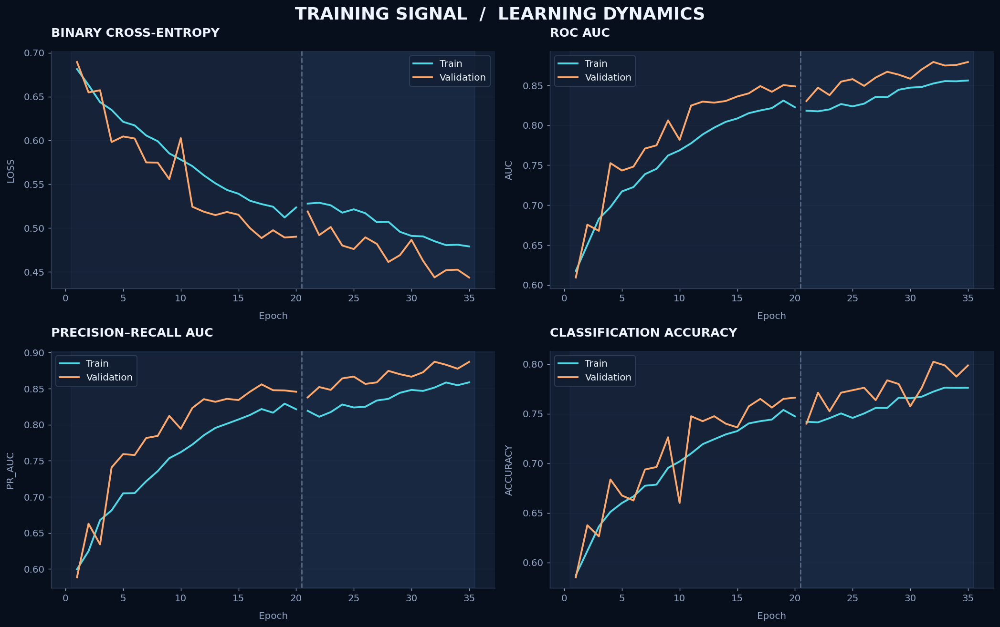

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), layout="constrained")
items = [("loss", "BINARY CROSS-ENTROPY", False), ("auc", "ROC AUC", True), ("pr_auc", "PRECISION–RECALL AUC", True), ("accuracy", "CLASSIFICATION ACCURACY", True)]
for ax, (metric, title, high_good) in zip(axes.flat, items):
    offset = 0
    for stage_number, (stage, hist) in enumerate(history_per_stage.items(), 1):
        n = len(hist[metric])
        epochs = np.arange(offset + 1, offset + n + 1)
        ax.plot(epochs, hist[metric], color=CYAN, lw=2.1, label="Train" if stage_number == 1 else None)
        ax.plot(epochs, hist[f"val_{metric}"], color=ORANGE, lw=2.1, label="Validation" if stage_number == 1 else None)
        ax.axvspan(epochs[0] - 0.5, epochs[-1] + 0.5, color="#5A7CB9", alpha=0.055 if stage_number == 1 else 0.12)
        if stage_number > 1:
            ax.axvline(offset + 0.5, color="#91A4C2", alpha=0.5, ls="--")
        offset += n
    decorate(ax, title, xlabel="Epoch", ylabel=metric.upper())
    ax.legend(loc="best", facecolor=PANEL_BG, labelcolor=WHITE, edgecolor="#354561")
fig.suptitle("TRAINING SIGNAL  /  LEARNING DYNAMICS", fontsize=20, fontweight="bold")
save_plot(fig, "03_training_dynamics")

In [10]:
def predict_frame(network, frame, size=320, variant="center"):
    dataset = image_dataset(frame, size, training=False, variant=variant)
    return network.predict(dataset, verbose=0).reshape(-1).astype(np.float64)

results = []
for stage_number in range(1, len(STAGES) + 1):
    candidate = K.models.load_model(str(CHECKPOINTS / f"stage{stage_number}_best.keras"), compile=False)
    scores = predict_frame(candidate, val_frame, size=320)
    ce = float(np.mean(-val_labels * np.log(np.clip(scores, 1e-7, 1-1e-7)) - (1-val_labels) * np.log(np.clip(1-scores, 1e-7, 1-1e-7))))
    auc = float(roc_auc_score(val_labels, scores))
    results.append((ce, -auc, stage_number, scores))
    print(f"Stage {stage_number} checked on shared 320px validation: BCE={ce:.5f} | AUC={auc:.5f}")
    del candidate
    gc.collect()

best_ce, negative_auc, best_stage, best_prob = min(results, key=lambda item: (item[0], item[1]))
model = K.models.load_model(str(CHECKPOINTS / f"stage{best_stage}_best.keras"), compile=False)
FINAL_MODEL = OUT / "best_model.keras"
model.save(str(FINAL_MODEL))
print(f"Selected stage {best_stage}; best model saved to {FINAL_MODEL}")

fpr, tpr, thresholds_roc = roc_curve(val_labels, best_prob)
selection = np.argmax(tpr - fpr)
THRESHOLD = float(np.clip(thresholds_roc[selection], 0.05, 0.95))
fixed_preds = (best_prob >= 0.5).astype(np.int32)
tuned_preds = (best_prob >= THRESHOLD).astype(np.int32)

def metric_table(y, scores, threshold):
    pred = (scores >= threshold).astype(int)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    return {
        "auc": float(roc_auc_score(y, scores)),
        "average_precision": float(average_precision_score(y, scores)),
        "accuracy": float(accuracy_score(y, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
        "f1_ai": float(f1_score(y, pred, zero_division=0)),
        "precision_ai": float(precision_score(y, pred, zero_division=0)),
        "recall_ai": float(recall_score(y, pred, zero_division=0)),
        "false_positive_rate": float(cm[0, 1] / max(1, sum(cm[0]))),
        "false_negative_rate": float(cm[1, 0] / max(1, sum(cm[1]))),
        "brier_score": float(brier_score_loss(y, scores)),
        "confusion_matrix_real_ai": cm.tolist()
    }

scores_fixed = metric_table(val_labels, best_prob, 0.5)
scores_tuned = metric_table(val_labels, best_prob, THRESHOLD)
print("DEFAULT 0.5 THRESHOLD:", json.dumps(scores_fixed, indent=2))
print(f"VALIDATION-TUNED THRESHOLD: {THRESHOLD:.4f}")
print("TUNED METRICS:", json.dumps(scores_tuned, indent=2))
print("Validation-tuned threshold is not an unbiased test performance estimate")

policy = {
    "model_file": "best_model.keras",
    "image_size": 320,
    "input_range": [0.0, 1.0],
    "class_names": ["Real", "AI-generated"],
    "positive_label": 1,
    "decision_threshold": THRESHOLD,
    "default_threshold": 0.5,
    "checkpoint_stage": best_stage,
    "data_leakage_removed": True,
    "model_is_pretrained": False,
    "validation_auc": scores_fixed["auc"],
    "validation_brier": scores_fixed["brier_score"],
    "requires_external_test": True,
    "caution": "Model score is not a verified probability of authenticity. Validation has severe acquisition-format confounding."
}
(OUT / "inference_config.json").write_text(json.dumps(policy, indent=2), encoding="utf-8")
val_results = val_frame[["path", "label", "extension", "decoded_format"]].copy()
val_results["ai_score"] = best_prob
val_results["predicted_0_5"] = fixed_preds
val_results["predicted_tuned"] = tuned_preds
val_results.to_csv(REPORTS / "validation_predictions.csv", index=False)

Stage 1 checked on shared 320px validation: BCE=0.48112 | AUC=0.84996
Stage 2 checked on shared 320px validation: BCE=0.43528 | AUC=0.87916
Selected stage 2; best model saved to /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts/best_model.keras
DEFAULT 0.5 THRESHOLD: {
  "auc": 0.8791625000000001,
  "average_precision": 0.8871075911736014,
  "accuracy": 0.79875,
  "balanced_accuracy": 0.7987500000000001,
  "f1_ai": 0.7995018679950187,
  "precision_ai": 0.7965260545905707,
  "recall_ai": 0.8025,
  "false_positive_rate": 0.205,
  "false_negative_rate": 0.1975,
  "brier_score": 0.14057048121633586,
  "confusion_matrix_real_ai": [
    [
      318,
      82
    ],
    [
      79,
      321
    ]
  ]
}
VALIDATION-TUNED THRESHOLD: 0.5687
TUNED METRICS: {
  "auc": 0.8791625000000001,
  "average_precision": 0.8871075911736014,
  "accuracy": 0.805,
  "balanced_accuracy": 0.8049999999999999,
  "f1_ai": 0.7963446475195822,
  "precision_ai": 0.8333333333333334,
  "recall

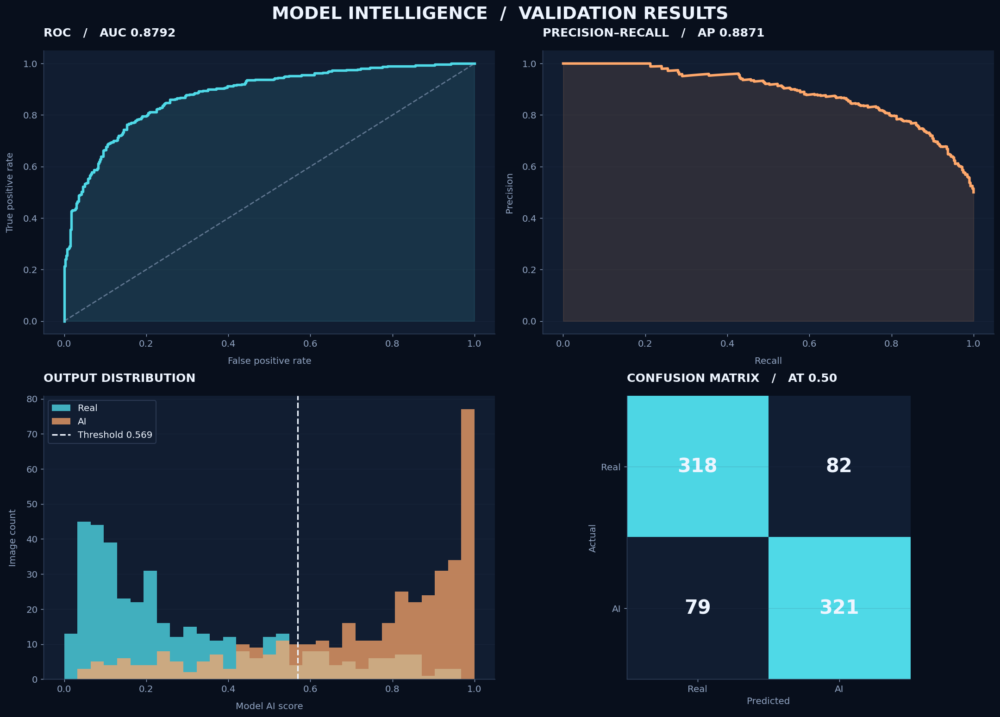

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16.5, 11.8), layout="constrained")
ax = axes[0, 0]
ax.plot(fpr, tpr, color=CYAN, lw=3)
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", alpha=0.6)
ax.fill_between(fpr, tpr, alpha=0.12, color=CYAN)
decorate(ax, f"ROC   /   AUC {scores_fixed['auc']:.4f}", xlabel="False positive rate", ylabel="True positive rate")
ax = axes[0, 1]
prec, rec, _ = precision_recall_curve(val_labels, best_prob)
ax.plot(rec, prec, color=ORANGE, lw=3)
ax.fill_between(rec, prec, color=ORANGE, alpha=0.12)
decorate(ax, f"PRECISION–RECALL   /   AP {scores_fixed['average_precision']:.4f}", xlabel="Recall", ylabel="Precision")
ax = axes[1, 0]
ax.hist(best_prob[val_labels == 0], bins=np.linspace(0, 1, 32), alpha=0.78, color=CYAN, label="Real")
ax.hist(best_prob[val_labels == 1], bins=np.linspace(0, 1, 32), alpha=0.73, color=ORANGE, label="AI")
ax.axvline(THRESHOLD, ls="--", color=WHITE, lw=1.8, label=f"Threshold {THRESHOLD:.3f}")
ax.legend(facecolor=PANEL_BG, labelcolor=WHITE, edgecolor="#354561")
decorate(ax, "OUTPUT DISTRIBUTION", xlabel="Model AI score", ylabel="Image count")
ax = axes[1, 1]
cm = np.asarray(scores_fixed["confusion_matrix_real_ai"])
ax.imshow(cm, cmap=LinearSegmentedColormap.from_list("custom", [PANEL_BG, "#206787", CYAN]))
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{cm[r, c]}", color=WHITE, ha="center", va="center", fontsize=23, weight="bold")
ax.set_xticks([0, 1], ["Real", "AI"])
ax.set_yticks([0, 1], ["Real", "AI"])
ax.set_xlabel("Predicted", color=MUTED)
ax.set_ylabel("Actual", color=MUTED)
ax.grid(False)
decorate(ax, "CONFUSION MATRIX   /   AT 0.50")
fig.suptitle("MODEL INTELLIGENCE  /  VALIDATION RESULTS", fontsize=21, fontweight="bold")
save_plot(fig, "04_validation_performance")

jpeg80       | AUC 0.8794 | Balanced acc 0.7900 | Flip rate 0.037 | Score drift 0.024
softened     | AUC 0.8764 | Balanced acc 0.8025 | Flip rate 0.043 | Score drift 0.030
corner_tl    | AUC 0.8784 | Balanced acc 0.7962 | Flip rate 0.036 | Score drift 0.033
corner_br    | AUC 0.8796 | Balanced acc 0.8062 | Flip rate 0.039 | Score drift 0.030


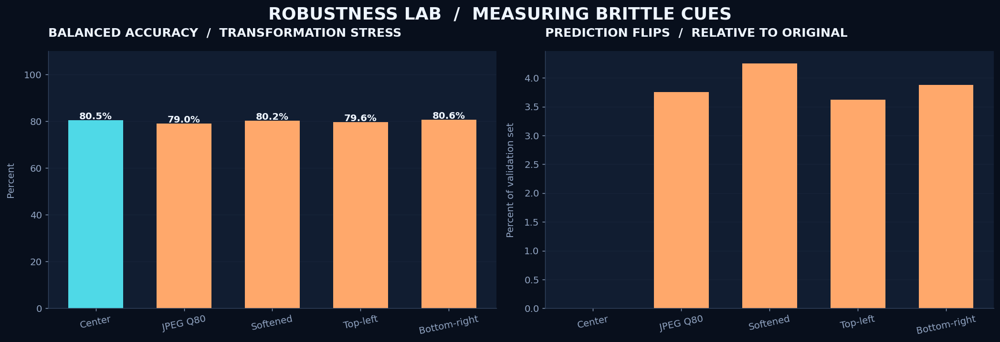

In [12]:
robust_results = []
robust_preds = {"center": best_prob}
for variant in ("jpeg80", "softened", "corner_tl", "corner_br"):
    scores = predict_frame(model, val_frame, size=320, variant=variant)
    robust_preds[variant] = scores
    met = metric_table(val_labels, scores, THRESHOLD)
    flips = float(np.mean((scores >= THRESHOLD) != (best_prob >= THRESHOLD)))
    drift = float(np.mean(np.abs(scores - best_prob)))
    robust_results.append({"variant": variant, **met, "prediction_flip_rate": flips, "mean_absolute_score_shift": drift})
    print(f"{variant:12s} | AUC {met['auc']:.4f} | Balanced acc {met['balanced_accuracy']:.4f} | Flip rate {flips:.3f} | Score drift {drift:.3f}")
robust_results.insert(0, {"variant": "center", **metric_table(val_labels, best_prob, THRESHOLD), "prediction_flip_rate": 0.0, "mean_absolute_score_shift": 0.0})
robust_frame = pd.DataFrame(robust_results)
robust_frame.to_csv(REPORTS / "robustness_validation.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), layout="constrained")
labels_v = ["Center", "JPEG Q80", "Softened", "Top-left", "Bottom-right"]
ax = axes[0]
bars = ax.bar(labels_v, 100 * robust_frame["balanced_accuracy"], color=[CYAN] + [ORANGE] * 4, width=0.62)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{bar.get_height():.1f}%", ha="center", color=WHITE, weight="bold")
ax.set_ylim(0, 110)
decorate(ax, "BALANCED ACCURACY  /  TRANSFORMATION STRESS", ylabel="Percent")
ax.tick_params(axis="x", rotation=12)
ax = axes[1]
ax.bar(labels_v, 100 * robust_frame["prediction_flip_rate"], color=[CYAN] + [ORANGE] * 4, width=0.62)
decorate(ax, "PREDICTION FLIPS  /  RELATIVE TO ORIGINAL", ylabel="Percent of validation set")
ax.tick_params(axis="x", rotation=12)
fig.suptitle("ROBUSTNESS LAB  /  MEASURING BRITTLE CUES", fontsize=20, fontweight="bold")
save_plot(fig, "05_robustness_stress")

ROC AUC 95% stratified bootstrap interval: [0.85549796875, 0.9020223437499998]
Tuned balanced accuracy 95% bootstrap interval: [0.77875, 0.8325]
These intervals do not account for validation-driven model/threshold selection or dataset shifts
Misclassified samples (tuned threshold): 156


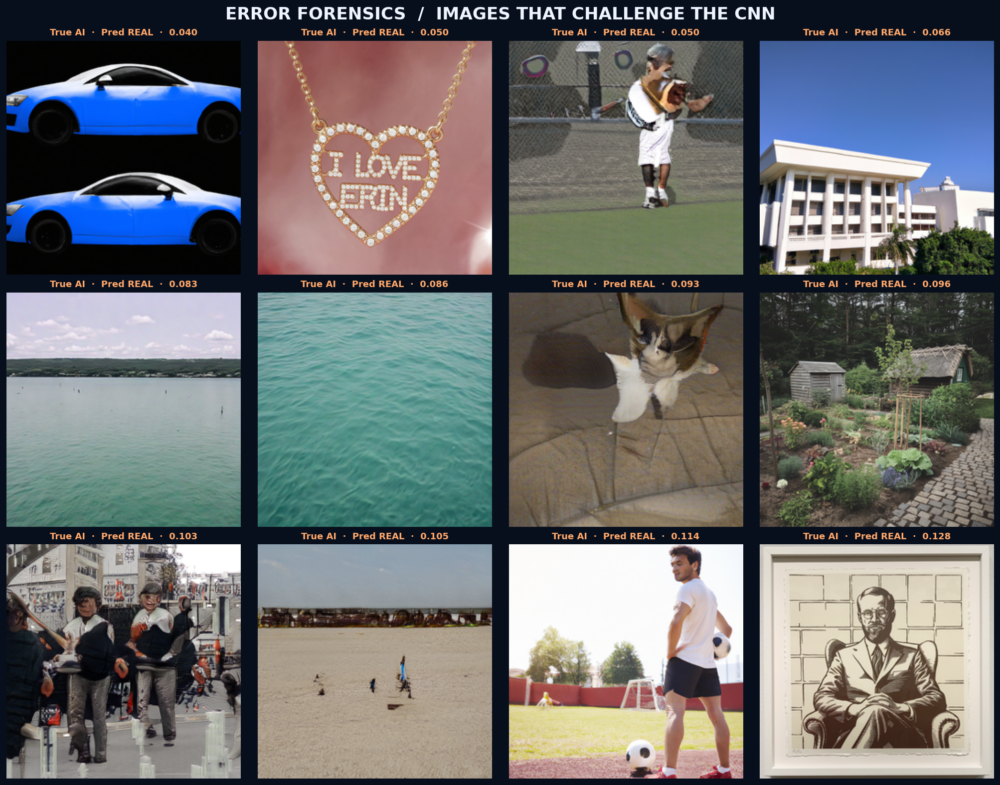

In [13]:
rng = np.random.default_rng(SEED)
bootstrap_auc = []
bootstrap_bal = []
real_idx = np.flatnonzero(val_labels == 0)
ai_idx = np.flatnonzero(val_labels == 1)
for iteration in range(1200):
    subset = np.r_[rng.choice(real_idx, len(real_idx), replace=True), rng.choice(ai_idx, len(ai_idx), replace=True)]
    bootstrap_auc.append(roc_auc_score(val_labels[subset], best_prob[subset]))
    bootstrap_bal.append(balanced_accuracy_score(val_labels[subset], tuned_preds[subset]))
interval_auc = np.quantile(bootstrap_auc, [0.025, 0.975]).tolist()
interval_bal = np.quantile(bootstrap_bal, [0.025, 0.975]).tolist()
print(f"ROC AUC 95% stratified bootstrap interval: {interval_auc}")
print(f"Tuned balanced accuracy 95% bootstrap interval: {interval_bal}")
print("These intervals do not account for validation-driven model/threshold selection or dataset shifts")

errors = val_results.loc[val_results["predicted_tuned"] != val_results["label"]].copy()
errors["error_strength"] = np.abs(errors["ai_score"] - THRESHOLD)
errors = errors.sort_values("error_strength", ascending=False)
errors.to_csv(REPORTS / "misclassified_validation_images.csv", index=False)
print(f"Misclassified samples (tuned threshold): {len(errors)}")

examples = errors.head(12)
if examples.empty:
    examples = val_results.iloc[np.argsort(np.abs(best_prob - THRESHOLD))[:12]]
fig, axes = plt.subplots(3, 4, figsize=(15.5, 12), layout="constrained")
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    sample_image = square_crop(rgb_open(DATASET / row["path"]), 256)
    ax.imshow(sample_image)
    label = "AI" if row["label"] == 1 else "REAL"
    predicted = "AI" if row["ai_score"] >= THRESHOLD else "REAL"
    ax.set_title(f"True {label}  ·  Pred {predicted}  ·  {row['ai_score']:.3f}", color=ORANGE if predicted != label else CYAN, fontsize=10)
    ax.axis("off")
for ax in list(axes.flat)[len(examples):]:
    ax.axis("off")
fig.suptitle("ERROR FORENSICS  /  IMAGES THAT CHALLENGE THE CNN", fontsize=19, fontweight="bold")
save_plot(fig, "06_hard_examples")

In [14]:
format_checks = []
for ext in sorted(val_frame["extension"].unique()):
    indices = np.flatnonzero(val_frame["extension"].to_numpy() == ext)
    subscores = best_prob[indices]
    sublabels = val_labels[indices]
    counts = Counter(sublabels)
    if len(counts) >= 2:
        result = metric_table(sublabels, subscores, THRESHOLD)
        print(f"VALIDATION FORMAT {ext}: real={counts[0]}, AI={counts[1]}, AUC={result['auc']:.4f}, balanced_acc={result['balanced_accuracy']:.4f}")
        format_checks.append({"extension": ext, "n_real": counts[0], "n_ai": counts[1], **result})
    else:
        print(f"VALIDATION FORMAT {ext}: only class {next(iter(counts))} present; no within-format AUC can be computed")
        format_checks.append({"extension": ext, "n_real": counts.get(0, 0), "n_ai": counts.get(1, 0), "auc": None, "balanced_accuracy": None})

(REPORTS / "format_conditioned_validation.json").write_text(json.dumps(format_checks, indent=2, default=int), encoding="utf-8")
print("With only 25 JPEG AI images and 2 PNG real images, these are stress diagnostics, not a definitive matched benchmark")

VALIDATION FORMAT .jpg: real=398, AI=25, AUC=0.9230, balanced_acc=0.8646
VALIDATION FORMAT .png: real=2, AI=375, AUC=0.7760, balanced_acc=0.6273
With only 25 JPEG AI images and 2 PNG real images, these are stress diagnostics, not a definitive matched benchmark


/Users/sam/Desktop/aiolearn/tf_env/lib/python3.11/site-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['normalized_rgb']
Received: inputs=Tensor(shape=(1, 320, 320, 3))
  warnings.warn(msg)


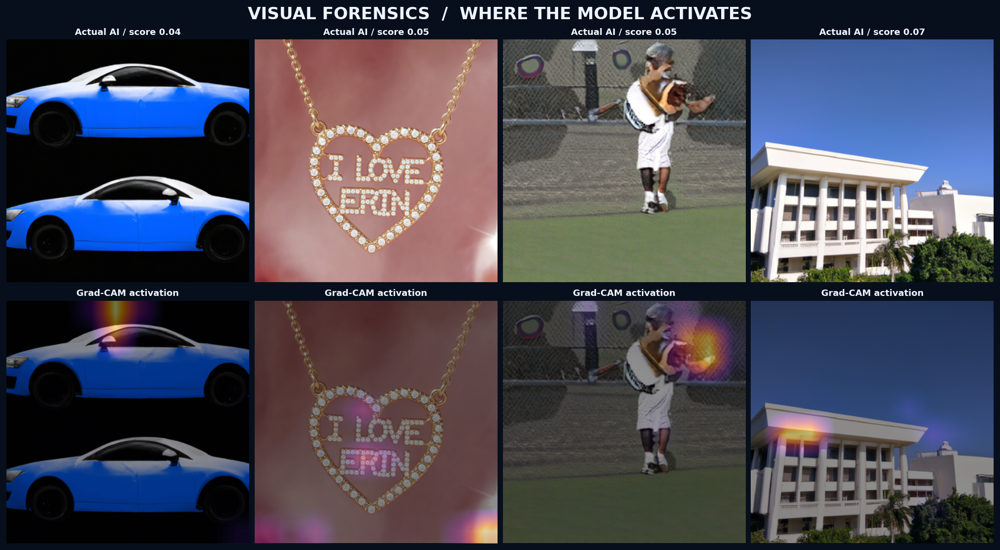

Grad-CAM is explanatory visualization, not proof of forensic causation


In [15]:
def gradcam_heatmap(network, rgb_array):
    last_conv = network.get_layer("forensic_features_conv")
    grad_model = K.Model(network.inputs, [last_conv.output, network.output])
    image_batch = tf.convert_to_tensor(rgb_array[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        features, output = grad_model(image_batch, training=False)
        objective = output[:, 0]
    gradients = tape.gradient(objective, features)
    channel_weight = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(features * channel_weight, axis=-1)[0]
    heatmap = tf.nn.relu(heatmap)
    max_val = tf.reduce_max(heatmap)
    heatmap = heatmap / (max_val + 1e-7)
    return np.asarray(heatmap.numpy(), dtype=np.float32)

cam_choices = errors.head(4) if len(errors) else val_results.iloc[np.argsort(np.abs(best_prob-THRESHOLD))[:4]]
fig, axes = plt.subplots(2, 4, figsize=(15.5, 8.5), layout="constrained")
for j, (_, item) in enumerate(cam_choices.iterrows()):
    original = np.asarray(square_crop(rgb_open(DATASET / item["path"]), 320), dtype=np.float32) / 255
    heat = gradcam_heatmap(model, original)
    axes[0, j].imshow(original)
    axes[1, j].imshow(original)
    axes[1, j].imshow(heat, cmap="inferno", alpha=0.45, interpolation="bilinear", extent=[0, 320, 320, 0], vmin=0, vmax=1)
    axes[0, j].set_title(f"Actual {'AI' if item['label'] else 'REAL'} / score {item['ai_score']:.2f}", fontsize=10)
    axes[1, j].set_title("Grad-CAM activation", fontsize=10)
for ax in axes.flat:
    ax.axis("off")
for ax in list(axes[0])[len(cam_choices):] + list(axes[1])[len(cam_choices):]:
    ax.axis("off")
fig.suptitle("VISUAL FORENSICS  /  WHERE THE MODEL ACTIVATES", fontsize=19, weight="bold")
save_plot(fig, "07_gradcam_visual_diagnostics")
print("Grad-CAM is explanatory visualization, not proof of forensic causation")

In [16]:
summary = {
    "selected_stage": best_stage,
    "train_images_after_leakage_control": int(len(train_frame)),
    "validation_images": int(len(val_frame)),
    "architecture": "CNN residual, random initialization, no pretrained weights",
    "trained_stages": STAGES,
    "threshold": THRESHOLD,
    "default_threshold_metrics": scores_fixed,
    "tuned_threshold_metrics": scores_tuned,
    "bootstrap_auc_95pct": interval_auc,
    "bootstrap_balanced_accuracy_tuned_95pct": interval_bal,
    "stress_tests": robust_results,
    "format_conditioned_validation": format_checks,
    "metadata_only_probe_auc": AUDIT_DATA["metadata_probe"]["auc"],
    "warnings": [
        "Validation real/AI classes are highly confounded with JPEG/PNG, pixel size and provenance",
        "High validation accuracy is not evidence of generalization to unseen generators or acquisition sources",
        "Image compression normalization cannot completely remove historical JPEG artifacts",
        "The validation split has been used for checkpoint and threshold selection",
        "A separate source-disjoint and codec-matched test set is still required"
    ]
}
(OUT / "evaluation_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("=" * 80)
print("TRAINING / REPORTING COMPLETE")
print("Model:", FINAL_MODEL)
print("Inference config:", OUT / "inference_config.json")
print("Training results:", OUT / "evaluation_summary.json")
print("Visual report directory:", REPORTS)
print("=" * 80)

TRAINING / REPORTING COMPLETE
Model: /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts/best_model.keras
Inference config: /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts/inference_config.json
Training results: /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts/evaluation_summary.json
Visual report directory: /Users/sam/Desktop/aiolearn/My_projects/Fake_vs_Real_Detector/model_artifacts/reports
